# Why is this molecule a time-dependent inhibitor?

This notebook asks the CYP3A4 model to justify a prediction, and checks that the
justification *is* the computation rather than a story told about it.

The model is one L2 logistic regression with 152 terms:

$$\mathrm{logit}\,p(\mathrm{TDI}) = b_0
 + \sum_i w_i\,z\!\left(\log(1+\text{count of Morgan environment }i)\right)
 + \sum_l c_l\,z(\text{physchem / MBI motif}_l)
 + \sum_j v_j\,z(\text{CASPER 3D surface}_j)
 + \sum_k u_k\,z(\text{Mordred}_k)$$

Because it is linear, the per-term contribution $w_i z_i$ is exactly what the
model added up. There is no surrogate model, no sampled background
distribution, and no additivity assumption that might not hold — the
explanation and the prediction are the same arithmetic. We verify that below
rather than asserting it.

In [1]:
import json, sys, numpy as np, pandas as pd
sys.path.insert(0, '..')
from IPython.display import SVG, HTML, display
from rdkit import Chem
from rdkit.Chem import Draw

from glassbox import FeatureSet, GlassBox, data as D, features as F, draw

pd.set_option('display.width', 180)
R = '..'
train = pd.read_csv(f'{R}/data/tdi_train.csv')
harv  = pd.read_csv(f'{R}/data/tdi_harvested.csv')
X, bits, prov = F.build_morgan(train.SMILES.tolist(), cache=f'{R}/features/morgan_train.pkl')

fs = FeatureSet(train.SMILES.tolist(), X, bits, prov,
                np.load(f'{R}/features/standard_train.npy'),
                np.load(f'{R}/features/casper_train.npy'),
                json.load(open(f'{R}/features/casper_names.json')),
                np.load(f'{R}/features/mordred_slim_train.npy'),
                json.load(open(f'{R}/features/mordred_slim_names.json')))

m3a4 = GlassBox.load(f'{R}/models/CYP3A4.json')
m2d6 = GlassBox.load(f'{R}/models/CYP2D6.json')
print(f'CYP3A4: {len(m3a4.terms)} terms, fitted on {m3a4.n_train} compounds')
print(f'CYP2D6: {len(m2d6.terms)} terms, fitted on {m2d6.n_train} compounds')
print(m3a4.operating_point)

CYP3A4: 152 terms, fitted on 2528 compounds
CYP2D6: 88 terms, fitted on 4213 compounds
{'rule': '1se', 'positive_rate': 0.46, 'prob_cut': 0.2576, 'cv_mcc_loso': 0.3253, 'cv_mcc_loso_sd': 0.0101, 'rate_seeds': '0-11', 'cv_seeds': '24-35'}


## A clear-cut case

Row 5138 is a pyridine bearing a **terminal alkyne**. Terminal alkynes are the
textbook mechanism-based inactivator: CYP oxidation gives a ketene (or oxirene)
that acylates the apoprotein or the heme, so the enzyme is destroyed rather than
reversibly blocked. 17α-ethynylestradiol is the classical example.

The experimental label says this compound is a CYP3A4 TDI. Let us see what the
model says, and *why*.

C#CC1=CC=NC(N(CC)C(=O)C2=CC=CC(OCCOC)=C2)=C1    experimental CYP3A4_is_TDI = 1.0


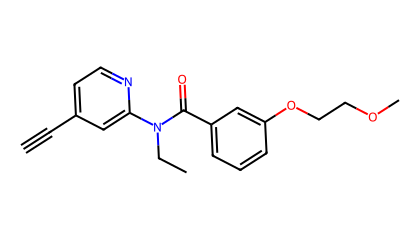

In [2]:
row = 5138
smi = train.SMILES[row]
print(smi, '   experimental CYP3A4_is_TDI =', train.CYP3A4_y[row])
display(Draw.MolToImage(Chem.MolFromSmiles(smi), size=(420, 240)))

In [3]:
e = m3a4.explain(fs, row)
print(GlassBox.summary(e, top=12))

CYP3A4  p(TDI) = 0.980   (baseline from the intercept alone 0.224)
logit = +3.917 = intercept -1.241 + 152 term contributions

  contrib  block     term
------------------------------------------------------------------------------
   +3.530  standard  terminal_alkyne
   +2.528  standard  internal_alkyne
   +0.679  mordred   fragCpx
   -0.507  morgan    N
   -0.467  casper    fraction of surface with mr in [3.50,4.00) [average over c
   -0.367  mordred   Xch-6d
   -0.232  standard  HBD
   -0.229  mordred   Xp-6dv
   +0.214  morgan    CCN
   -0.193  casper    eneg surface autocorrelation at [6.0,7.5) A (how often two
   -0.181  mordred   ATS1p
   +0.165  morgan    cc(c)O
------------------------------------------------------------------------------
           pushing TOWARD TDI +9.530 / AWAY -4.372
           by block: standard=+5.66  mordred=+0.02  morgan=-0.29  casper=-0.23


The model's two largest terms are the terminal-alkyne and internal-alkyne flags,
together worth **+6.1 in log-odds** — they move the molecule from the model's
baseline rate of 22% to 98%. That is the right answer for the right reason, and
nothing in the pipeline was told that alkynes matter: those two motifs sit in a
30-member panel of literature mechanism-based-inactivation substructures that
was fixed *before* any model was fitted, and the coefficients on them were
learned from the data like every other term.

A waterfall of the same numbers:

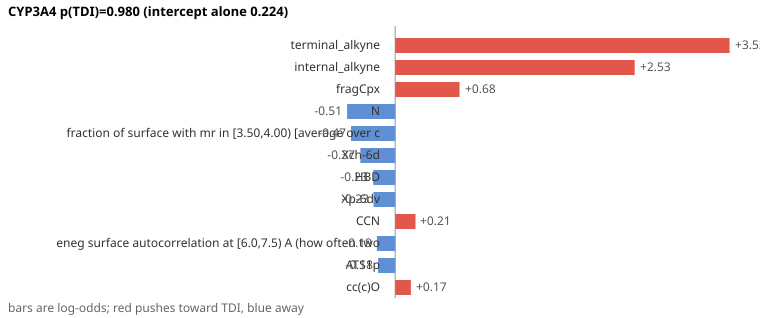

In [4]:
display(SVG(draw.waterfall(e, top=12)))

### The explanation is the computation

For a linear model this is checkable, so check it. The claim is that

$$\mathrm{logit} = b_0 + \sum_t \mathrm{contribution}_t,
\qquad \mathrm{contribution}_t = w_t\,\frac{x_t - \mu_t}{\sigma_t}$$

holds exactly — not approximately, not in expectation over a background set.

In [5]:
logit_from_terms = e.attrs['intercept'] + e.contribution.sum()
p_from_terms     = 1 / (1 + np.exp(-logit_from_terms))
p_from_model     = m3a4.predict_proba(fs, [row])[0]

print(f'intercept + sum(contributions) = {logit_from_terms:.12f}')
print(f'model logit                    = {e.attrs["logit"]:.12f}')
print(f'p from the explanation         = {p_from_terms:.12f}')
print(f'p from the model               = {p_from_model:.12f}')
print(f'exact to floating point        = {np.isclose(p_from_terms, p_from_model, atol=1e-12)}')

# and one term, recomputed from the saved JSON by hand
t = next(t for t in m3a4.terms if t['name'] == 'terminal_alkyne')
x = e.loc[e.term == 'terminal_alkyne', 'value'].iloc[0]
print(f"\nby hand: coef {t['coef']:.6f} * (value {x:.1f} - center {t['center']:.6f})"
      f" / scale {t['scale']:.6f} = {t['coef']*(x-t['center'])/t['scale']:+.6f}")
print('from explain():', f"{e.loc[e.term=='terminal_alkyne','contribution'].iloc[0]:+.6f}")

intercept + sum(contributions) = 3.916564275853
model logit                    = 3.916564275853
p from the explanation         = 0.980479265225
p from the model               = 0.980479265225
exact to floating point        = True

by hand: coef 0.099337 * (value 1.0 - center 0.000791) / scale 0.028116 = +3.530303
from explain(): +3.530303


## A case where the *learned* terms do the work

The alkyne example leans on the a-priori motif panel, so it does not show what
unfolding the fingerprint bought. Row 4081 does: **no alert in the panel fires
for its reactive moiety**, and the call is carried by learned Morgan
environments.

CC1=CC=C(Cl)C=C1N1CCC(CNC(=O)C2=CC=CN3C(=O)NN=C23)C1    experimental CYP3A4_is_TDI = 1.0
a-priori motifs that fire: ['aniline_sec_tert', 'pyridine']


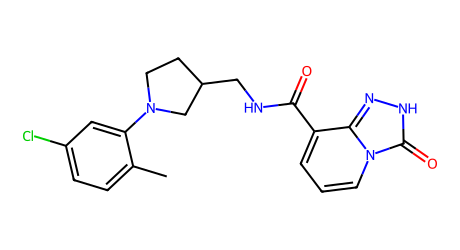

CYP3A4  p(TDI) = 0.972   (baseline from the intercept alone 0.224)
logit = +3.541 = intercept -1.241 + 152 term contributions

  contrib  block     term
------------------------------------------------------------------------------
   +1.586  morgan    cc(n)n
   +0.881  morgan    cccc(c)C
   +0.505  morgan    cN(C)C
   -0.476  mordred   fragCpx
   +0.335  morgan    N
   +0.330  casper    fraction of surface with estate in [8.33,10.00) [variation
   +0.303  morgan    c[nH]n
   +0.271  morgan    cn[nH]
   +0.267  morgan    cc(c)C
   +0.231  morgan    N
------------------------------------------------------------------------------
           pushing TOWARD TDI +7.189 / AWAY -2.407
           by block: morgan=+4.49  mordred=-0.38  casper=+0.44  standard=+0.23


In [6]:
row2 = 4081
smi2 = train.SMILES[row2]
mol2 = Chem.MolFromSmiles(smi2)
print(smi2, '   experimental CYP3A4_is_TDI =', train.CYP3A4_y[row2])
print('a-priori motifs that fire:', [k for k, v in F.PAT.items() if mol2.HasSubstructMatch(v)])
display(Draw.MolToImage(mol2, size=(460, 250)))

e2 = m3a4.explain(fs, row2)
print(GlassBox.summary(e2, top=10))

`cc(n)n` at **+1.59** is the single largest term, and the whole Morgan block
contributes **+4.49** against **+0.23** from the a-priori panel. That environment
is an aminopyrazole/triazolone-type carbon — a real substructure the model
learned on its own.

And because the fingerprint was never hashed, the coefficient *is* a
substructure, so it can be drawn on the molecule that triggered it:

In [7]:
svgs, rows_drawn = draw.highlight_terms(smi2, e2, top=6)
display(HTML(draw.grid(svgs, per_row=3)))
print(rows_drawn[['term', 'radius', 'value', 'coef', 'contribution']].to_string(index=False))

    term  radius    value     coef  contribution
  cc(n)n       1 0.693147 0.255619      1.586077
cccc(c)C       2 0.693147 0.140814      0.880815
  cN(C)C       1 0.693147 0.174456      0.505480
       N       0 1.098612 0.339691      0.334761
  c[nH]n       1 0.693147 0.070523      0.303442
  cn[nH]       1 0.693147 0.059781      0.270729


This is what a conventional folded ECFP cannot do. Hashing ~23,000 distinct
radius-2 environments into 2,048 bits means a coefficient belongs to a collision
bucket, so it has no single substructure to point at. Keeping the fingerprint
sparse and unfolded costs nothing and was the largest single win in the project
(CYP3A4 0.2573 → 0.3090).

## What the 3D block sees

CASPER maps atomic properties onto the molecular surface and encodes them as
histograms plus spatial autocorrelations, pooled over a conformer ensemble. The
selection ran separately per isoform, with no protein structure supplied — and
it chose **different length scales for the two enzymes**.

In [8]:
def ac_scales(m):
    out = []
    for t in m.terms:
        if t['block'] == 'casper' and '|ac[' in t['name']:
            lo, hi = t['name'].split('|ac[')[1].rstrip(')A').split(',')
            out.append(((float(lo) + float(hi)) / 2, t['name'], t['coef']))
    return sorted(out)

for name, m in [('CYP2D6', m2d6), ('CYP3A4', m3a4)]:
    sc = ac_scales(m)
    print(f'{name}: {len(sc)} surface-autocorrelation terms, '
          f'median distance {np.median([s[0] for s in sc]):.1f} A')
    for d, nm, c in sc:
        print(f'    {d:5.1f} A   {c:+.3f}   {nm}')
    print()

CYP2D6: 9 surface-autocorrelation terms, median distance 5.2 A
      2.2 A   +0.020   std:tpsa|ac[1.5,3.0)A
      3.8 A   +0.046   mean:abs_charge|ac[3.0,4.5)A
      3.8 A   -0.022   mean:logp|ac[3.0,4.5)A
      3.8 A   -0.231   std:abs_charge|ac[3.0,4.5)A
      5.2 A   +0.027   mean:tpsa|ac[4.5,6.0)A
      5.2 A   -0.188   std:gasteiger|ac[4.5,6.0)A
      5.2 A   +0.079   std:mmff_charge|ac[4.5,6.0)A
      6.8 A   -0.003   std:hba|ac[6.0,7.5)A
      8.2 A   +0.164   mean:logp|ac[7.5,9.0)A

CYP3A4: 19 surface-autocorrelation terms, median distance 6.8 A
      0.8 A   -0.190   mean:tpsa|ac[0.0,1.5)A
      3.8 A   +0.042   std:mmff_charge|ac[3.0,4.5)A
      5.2 A   -0.034   mean:abs_charge|ac[4.5,6.0)A
      5.2 A   +0.009   mean:logp|ac[4.5,6.0)A
      5.2 A   +0.032   std:hba|ac[4.5,6.0)A
      5.2 A   +0.009   std:mmff_charge|ac[4.5,6.0)A
      5.2 A   +0.046   std:tpsa|ac[4.5,6.0)A
      6.8 A   +0.477   mean:eneg|ac[6.0,7.5)A
      6.8 A   -0.128   mean:hba|ac[6.0,7.5)A
      6.8 A 

Read the table above carefully, because the effect is real but narrower than a
headline would make it.

**Every CYP2D6 charge-organisation term sits within 5.2 Å** (`abs_charge` at
3.8 Å, `gasteiger` and `mmff_charge` at 5.2 Å), and no CYP2D6 term of any kind
reaches past 8.2 Å. **CYP3A4's extend to 11.2 Å**, and the long-range ones carry
real weight: `mean:logp|ac[9.0,10.5)A` at −0.226, `std:mmff_charge|ac[9.0,10.5)A`
at −0.164, and `mean:aromatic|ac[10.5,12.0)A` at +0.160 — two aromatic surfaces
about 11 Å apart, which is the ketoconazole/ritonavir shape. That last term is
stable in 97% of bootstrap refits.

The medians are less dramatic than the extremes (5.2 Å vs 6.8 Å), so the honest
summary is about **reach**, not about where the mass sits: the compact enzyme's
model never needed a distance beyond 8 Å, and the open one's did.

That is consistent with what is known about the two active sites — CYP2D6's is
small and compact, CYP3A4's is large enough to bind ketoconazole or ritonavir —
and the model was given no protein structure, no docking, and no binding-site
information of any kind. It is a recovered consistency, not a prediction of
structure, and the selection was run independently per isoform.

The `std:` terms deserve a note of their own: they measure how much a feature
*moves* across the conformer ensemble, so a negative coefficient on one says
electrostatically pre-organised, rigid molecules are likelier inactivators. That
signal only exists because the descriptor pools with `conf_pool=('mean','std')`.

In [9]:
terms = pd.DataFrame(m3a4.terms)
print(f'CYP3A4: {len(terms)} terms, {terms.block.value_counts().to_dict()}')
print(f'the saved model file is {len(open(f"{R}/models/CYP3A4.json").readlines())} lines of JSON\n')
print('largest 12 coefficients (not contributions -- these are the model, not one prediction):')
print(terms.reindex(terms.coef.abs().sort_values(ascending=False).index)
          .head(12)[['block', 'name', 'coef']].to_string(index=False))

CYP3A4: 152 terms, {'morgan': 64, 'standard': 40, 'casper': 32, 'mordred': 16}
the saved model file is 1400 lines of JSON

largest 12 coefficients (not contributions -- these are the model, not one prediction):
   block                            name      coef
 mordred                         fragCpx -0.549952
  casper          mean:eneg|ac[6.0,7.5)A  0.477342
 mordred                           ATS1p  0.357169
  morgan                              CO -0.356766
  morgan                               N  0.339691
  morgan                             cnn -0.335357
 mordred                          Xch-6d  0.311039
 mordred                           SLogP  0.295462
standard                             HBA -0.294206
  casper mean:abs_charge|hist[0.04,0.08)  0.257245
  morgan                          cc(n)n  0.255619
  morgan                             CCN -0.255391


That is the entire CYP3A4 model. Every row is a substructure you can draw, a
physical property, a named 2D descriptor, or a surface feature with a length
scale — and the prediction for any molecule is their weighted sum plus an
intercept.

**A caveat worth stating.** Individual coefficients in correlated groups are not
individually reproducible: bootstrap-refit stability runs from 13% to 100% across
these terms. A term at 25% stability is a placeholder for a correlated family,
not *the* chosen feature. The model's predictions are stable; the attribution of
credit within a correlated group is not, and no interpretability method can make
it so. What the low-stability terms do tell you reliably is which *kind* of
feature is carrying signal.